# RIN — experiment 7a: hybrid transfer on a seeded embryonic subgraph

This notebook tests whether the 6c-6d retrieval picture transfers from
hand-authored synthetic graphs to a larger real seeded embryonic
subgraph:

`score = inflow × retention correction × global surprise correction`

In practice here:

- `inflow` is the existing semantic-gated diffusion field;
- `retention correction` is the transferable local leak term
  `1 / (alpha + beta * s_out^gamma)`;
- `global surprise correction` is either `1 / in_strength^eta` or
  `1 / PageRank^eta`.

The notebook is intentionally scoped to a **seeded** subgraph rather
than the full embryonic graph, so the topology remains inspectable while
still showing real fame / hub structure.

In [1]:
import sys
from pathlib import Path

def find_repo_root(marker="requirements.txt"):
    # Notebook now lives in src/experiments/, whose cwd in Jupyter is
    # usually the notebook's own directory, not the repo root — walk up
    # until a known repo-root marker is found, instead of assuming cwd.
    path = Path.cwd()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"could not find repo root (looked for {marker})")

REPO_ROOT = find_repo_root()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

In [2]:
from __future__ import annotations

from collections import Counter
from pathlib import Path
import math
import re

import numpy as np

from embryonic import conceptnet_source
from embryonic.loader import EmbryonicGraphLoader
from embryonic.numberbatch import Numberbatch
from embryonic.query import longest_match_terms, query_vectors
from memory.diffuse import diffuse
from memory.graph import MemoryGraph
from memory.pagerank import (
    in_strength_prior,
    out_strength_prior,
    weighted_in_strengths,
    weighted_out_strengths,
    weighted_pagerank,
)
from memory.retrieval import nearest_nodes_by_embedding

try:
    import matplotlib.pyplot as plt
except Exception:
    plt = None

try:
    import networkx as nx
except Exception:
    nx = None

In [3]:
SOURCE_DIR = REPO_ROOT / "source"

CONCEPTNET_DUMP = SOURCE_DIR / "conceptnet-assertions-5.7.0.csv.gz"
ATOMIC_CSV = SOURCE_DIR / "v4_atomic_all_agg.csv"
NUMBERBATCH_FILE = SOURCE_DIR / "numberbatch-en-19.08.txt.gz"

LANGUAGE = "en"
CONCEPTNET_BACKEND = "local_dump"
INCLUDE_ATOMIC = True
ATOMIC_FUZZY_LINKING = False

SEED_ENTRIES = [
    "coffee",
    "caffeine",
    "beverage",
    "energy",
    "water",
    "passport",
    "boarding pass",
    "check in",
    "airport",
    "travel",
    "hotel",
    "laptop",
    "charger",
    "office",
    "apartment",
    "wallet",
    "keys",
    "cats",
    "umbrella",
    "outdoor gear",
    "breakfast",
    "wake up",
    "espresso",
]

BASE_RADIUS = 3
ALT_RADIUS = 4
LIMIT_PER_NODE = 30
MAX_NODES = 10_000
MIN_RELATED_TO_WEIGHT = 2.0

SOURCE_AMPLITUDE = 100.0
DIFFUSE_KW = {
    "decay": 0.8,
    "min_propagate_fraction": 0.01,
    "max_steps": 20,
}
ANCHOR_TOP_K = 3
ANCHOR_MIN_SIMILARITY = 0.3

RUN_OPTIONAL_M5 = False
RUN_RADIUS_4 = False
VISUALIZE_SAMPLE_QUERY = "Q1"

TERM_VARIANTS = {
    "home": ["home", "home life"],
    "work": ["work", "office", "work setup"],
    "travel": ["travel", "travel planning", "trip"],
    "trip": ["trip", "travel planning", "travel"],
    "boarding pass": ["boarding pass", "boarding_pass"],
    "check in": ["check in", "check_in"],
    "outdoor gear": ["outdoor gear", "outdoor_gear"],
    "wake up": ["wake up", "wake_up"],
}

QUERY_SPECS = [
    {
        "id": "Q1",
        "query": "why coffee gives energy",
        "correct": ["caffeine", "coffee"],
        "distractors": ["beverage", "water"],
        "pairwise": [("caffeine", "beverage"), ("coffee", "water")],
    },
    {
        "id": "Q2",
        "query": "what matters at check in",
        "correct": ["passport", "boarding pass"],
        "distractors": ["travel", "airport"],
        "pairwise": [("passport", "travel"), ("boarding pass", "airport")],
    },
    {
        "id": "Q3",
        "query": "what helps after dead laptop",
        "correct": ["charger"],
        "distractors": ["office", "work"],
        "pairwise": [("charger", "office")],
    },
    {
        "id": "Q4",
        "query": "what did i forget at home",
        "correct": ["wallet", "keys"],
        "distractors": ["apartment", "home", "cats"],
        "pairwise": [("wallet", "apartment"), ("keys", "cats")],
    },
    {
        "id": "Q5",
        "query": "tell me about apartment life",
        "correct": ["apartment", "home"],
        "distractors": ["wallet", "keys"],
        "pairwise": [("apartment", "wallet"), ("home", "keys")],
    },
    {
        "id": "Q6",
        "query": "tell me about travel planning",
        "correct": ["travel", "trip", "airport"],
        "distractors": ["passport"],
        "pairwise": [("travel", "passport"), ("trip", "passport")],
    },
    {
        "id": "Q7",
        "query": "what to drink in the morning",
        "correct": ["espresso", "coffee"],
        "distractors": ["water", "beverage"],
        "pairwise": [("espresso", "water"), ("coffee", "beverage")],
    },
]

METHODS = [
    {
        "name": "M0_raw",
        "label": "M0 raw diffusion",
        "kind": "raw",
    },
    {
        "name": "M1_in_strength_05",
        "label": "M1 raw + in-strength^0.5",
        "kind": "in_strength",
        "eta": 0.5,
    },
    {
        "name": "M2_pagerank_025",
        "label": "M2 raw + PageRank^0.25",
        "kind": "pagerank",
        "eta": 0.25,
    },
    {
        "name": "M2_pagerank_05",
        "label": "M2 raw + PageRank^0.5",
        "kind": "pagerank",
        "eta": 0.5,
    },
    {
        "name": "M3_local_leak",
        "label": "M3 local leak only",
        "kind": "local_leak",
        "alpha": 1.0,
        "beta": 0.05,
        "gamma": 0.5,
    },
    {
        "name": "M4_hybrid_pagerank",
        "label": "M4 local leak + PageRank^0.25",
        "kind": "hybrid_pagerank",
        "alpha": 1.0,
        "beta": 0.05,
        "gamma": 0.5,
        "eta": 0.25,
    },
]

if RUN_OPTIONAL_M5:
    METHODS.append(
        {
            "name": "M5_hybrid_in_strength",
            "label": "M5 local leak + in-strength^0.5",
            "kind": "hybrid_in_strength",
            "alpha": 1.0,
            "beta": 0.05,
            "gamma": 0.5,
            "eta": 0.5,
        }
    )

In [4]:
required_paths = [CONCEPTNET_DUMP, NUMBERBATCH_FILE]
if INCLUDE_ATOMIC:
    required_paths.append(ATOMIC_CSV)

missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing required local source files:\n" + "\n".join(str(path) for path in missing)
    )

print("All required source files are present.")
print(f"ConceptNet dump: {CONCEPTNET_DUMP}")
print(f"ATOMIC CSV:      {ATOMIC_CSV if INCLUDE_ATOMIC else '(disabled)'}")
print(f"Numberbatch:     {NUMBERBATCH_FILE}")

print("\nBuilding ConceptNet adjacency index once for reuse...")
adjacency = conceptnet_source.build_language_adjacency(str(CONCEPTNET_DUMP), LANGUAGE)
print(f"Indexed {len(adjacency):,} ConceptNet adjacency lists.")

print("\nLoading Numberbatch...")
numberbatch = Numberbatch()
numberbatch.load(str(NUMBERBATCH_FILE))
print(f"Loaded {len(numberbatch.terms):,} Numberbatch entries.")

All required source files are present.
ConceptNet dump: c:\Users\yaros\BlackSabbitch_repo\RIN\source\conceptnet-assertions-5.7.0.csv.gz
ATOMIC CSV:      c:\Users\yaros\BlackSabbitch_repo\RIN\source\v4_atomic_all_agg.csv
Numberbatch:     c:\Users\yaros\BlackSabbitch_repo\RIN\source\numberbatch-en-19.08.txt.gz

Building ConceptNet adjacency index once for reuse...
Indexed 1,787,373 ConceptNet adjacency lists.

Loading Numberbatch...
Loaded 516,782 Numberbatch entries.


In [5]:
def normalize_text(text: str) -> str:
    text = text.lower().replace("_", " ").strip()
    text = re.sub(r"\s+\([anvr]\)$", "", text)
    text = re.sub(r"\s+", " ", text)
    return text


def concept_term_from_provenance(uri: str) -> str | None:
    parts = uri.split("/")
    if len(parts) > 3 and parts[1] == "c":
        return parts[3].replace("_", " ")
    return None


def node_sort_key(G: MemoryGraph, node_id: int) -> tuple:
    node = G.nodes[node_id]
    content = normalize_text(node.content)
    is_concept = 0 if node.node_kind == "concept" else 1
    has_pos_suffix = 1 if "(" in node.content else 0
    return (is_concept, has_pos_suffix, len(content), node_id)


def build_label_index(G: MemoryGraph) -> dict[str, list[int]]:
    label_index: dict[str, list[int]] = {}
    for node_id, node in G.nodes.items():
        labels = {normalize_text(node.content)}
        for item in node.provenance:
            if isinstance(item, str):
                term = concept_term_from_provenance(item)
                if term is not None:
                    labels.add(normalize_text(term))
        for label in labels:
            if not label:
                continue
            label_index.setdefault(label, []).append(node_id)
    return label_index


def choose_best_node(G: MemoryGraph, node_ids: list[int]) -> int | None:
    if not node_ids:
        return None
    return sorted(set(node_ids), key=lambda node_id: node_sort_key(G, node_id))[0]


def resolve_term(G: MemoryGraph, label_index: dict[str, list[int]], term: str) -> tuple[int | None, str | None]:
    variants = TERM_VARIANTS.get(term, [term])
    variants = [term, *[variant for variant in variants if variant != term]]
    for variant in variants:
        node_ids = label_index.get(normalize_text(variant), [])
        chosen = choose_best_node(G, node_ids)
        if chosen is not None:
            return chosen, variant
    return None, None


def node_label(G: MemoryGraph, node_id: int) -> str:
    node = G.nodes[node_id]
    return f"{node.content} [{node.node_kind}]"


def exact_anchor_ids(
    G: MemoryGraph, label_index: dict[str, list[int]], matched_terms: list[str]
) -> list[int]:
    anchors: set[int] = set()
    for term_uri in matched_terms:
        term = concept_term_from_provenance(term_uri)
        if term is None:
            continue
        chosen = choose_best_node(G, label_index.get(normalize_text(term), []))
        if chosen is not None:
            anchors.add(chosen)
    return sorted(anchors)


def anchors_for_query(G: MemoryGraph, label_index: dict[str, list[int]], query_text: str) -> dict:
    matched_terms = longest_match_terms(query_text, numberbatch, language=LANGUAGE)
    anchors: set[int] = set()
    trace: list[dict] = []
    for term_uri in matched_terms:
        vec = numberbatch.vector_for(term_uri)
        if vec is None:
            continue
        hits = nearest_nodes_by_embedding(
            G,
            vec,
            top_k=ANCHOR_TOP_K,
            min_similarity=ANCHOR_MIN_SIMILARITY,
        )
        anchors.update(hits)
        trace.append(
            {
                "term": term_uri,
                "hits": [node_label(G, node_id) for node_id in hits],
            }
        )
    if not anchors and matched_terms:
        anchors.update(exact_anchor_ids(G, label_index, matched_terms))
    return {
        "matched_terms": matched_terms,
        "anchor_ids": sorted(anchors),
        "trace": trace,
    }


def print_table(rows: list[dict], columns: list[str]) -> None:
    if not rows:
        print("(no rows)")
        return
    widths = {}
    for column in columns:
        widths[column] = max(len(column), *(len(str(row.get(column, ""))) for row in rows))
    header = " | ".join(column.ljust(widths[column]) for column in columns)
    rule = "-+-".join("-" * widths[column] for column in columns)
    print(header)
    print(rule)
    for row in rows:
        print(" | ".join(str(row.get(column, "")).ljust(widths[column]) for column in columns))


def top_k_concepts(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[tuple[int, float]]:
    concept_rows = [
        (node_id, score)
        for node_id, score in scores.items()
        if G.nodes[node_id].node_kind == "concept"
    ]
    return sorted(concept_rows, key=lambda item: item[1], reverse=True)[:k]


def format_top_k(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[str]:
    return [f"{node_label(G, node_id)} :: {score:.4f}" for node_id, score in top_k_concepts(G, scores, k=k)]


def method_denominator(
    node_id: int,
    method: dict,
    out_strengths: dict[int, float],
    priors: dict[str, dict[int, float]],
) -> float:
    kind = method["kind"]
    denominator = 1.0
    if kind in {"local_leak", "hybrid_pagerank", "hybrid_in_strength"}:
        denominator *= method["alpha"] + method["beta"] * (out_strengths[node_id] ** method["gamma"])
    if kind in {"in_strength", "hybrid_in_strength"}:
        denominator *= priors["in_strength"][node_id] ** method["eta"]
    if kind in {"pagerank", "hybrid_pagerank"}:
        denominator *= priors["pagerank"][node_id] ** method["eta"]
    return denominator


def apply_method(
    base_scores: dict[int, float],
    method: dict,
    out_strengths: dict[int, float],
    priors: dict[str, dict[int, float]],
) -> dict[int, float]:
    if method["kind"] == "raw":
        return dict(base_scores)
    adjusted: dict[int, float] = {}
    for node_id, score in base_scores.items():
        denominator = method_denominator(node_id, method, out_strengths, priors)
        adjusted[node_id] = score / denominator if denominator > 0 else score
    return adjusted


def best_score(scores: dict[int, float], node_ids: list[int]) -> tuple[int | None, float | None]:
    present = [(node_id, scores.get(node_id, 0.0)) for node_id in node_ids]
    if not present:
        return None, None
    return max(present, key=lambda item: item[1])


def evaluate_query(
    G: MemoryGraph,
    label_index: dict[str, list[int]],
    spec: dict,
    scores: dict[int, float],
    anchor_info: dict,
) -> dict:
    resolved_correct = []
    missing_correct = []
    for term in spec["correct"]:
        node_id, resolved_as = resolve_term(G, label_index, term)
        if node_id is None:
            missing_correct.append(term)
        else:
            resolved_correct.append({"term": term, "resolved_as": resolved_as, "node_id": node_id})

    resolved_distractors = []
    missing_distractors = []
    for term in spec["distractors"]:
        node_id, resolved_as = resolve_term(G, label_index, term)
        if node_id is None:
            missing_distractors.append(term)
        else:
            resolved_distractors.append({"term": term, "resolved_as": resolved_as, "node_id": node_id})

    correct_ids = [item["node_id"] for item in resolved_correct]
    distractor_ids = [item["node_id"] for item in resolved_distractors]
    best_correct_id, best_correct_score = best_score(scores, correct_ids)
    best_distractor_id, best_distractor_score = best_score(scores, distractor_ids)

    solved = None
    margin = None
    if best_correct_score is not None and best_distractor_score is not None:
        solved = best_correct_score > best_distractor_score
        margin = best_correct_score - best_distractor_score

    pairwise_rows = []
    for left_term, right_term in spec["pairwise"]:
        left_id, left_resolved = resolve_term(G, label_index, left_term)
        right_id, right_resolved = resolve_term(G, label_index, right_term)
        passed = None
        if left_id is not None and right_id is not None:
            passed = scores.get(left_id, 0.0) > scores.get(right_id, 0.0)
        pairwise_rows.append(
            {
                "left_term": left_term,
                "left_resolved": left_resolved,
                "right_term": right_term,
                "right_resolved": right_resolved,
                "passed": passed,
            }
        )

    return {
        "id": spec["id"],
        "query": spec["query"],
        "matched_terms": anchor_info["matched_terms"],
        "anchor_ids": anchor_info["anchor_ids"],
        "anchor_labels": [node_label(G, node_id) for node_id in anchor_info["anchor_ids"]],
        "resolved_correct": resolved_correct,
        "resolved_distractors": resolved_distractors,
        "missing_correct": missing_correct,
        "missing_distractors": missing_distractors,
        "best_correct_id": best_correct_id,
        "best_correct_score": best_correct_score,
        "best_distractor_id": best_distractor_id,
        "best_distractor_score": best_distractor_score,
        "solved": solved,
        "margin": margin,
        "pairwise": pairwise_rows,
        "top10": format_top_k(G, scores, k=10),
        "top20": format_top_k(G, scores, k=20),
    }


def summarize_method(results: list[dict]) -> dict:
    solved_known = [row["solved"] for row in results if row["solved"] is not None]
    margins = [row["margin"] for row in results if row["margin"] is not None]
    pairwise_values = [
        pair["passed"]
        for row in results
        for pair in row["pairwise"]
        if pair["passed"] is not None
    ]
    return {
        "queries_with_decision": len(solved_known),
        "solved_queries": sum(1 for value in solved_known if value),
        "pairwise_total": len(pairwise_values),
        "pairwise_passed": sum(1 for value in pairwise_values if value),
        "total_margin": sum(margins),
    }


def loader_for_radius(radius: int) -> EmbryonicGraphLoader:
    return EmbryonicGraphLoader(
        entries=SEED_ENTRIES,
        radius=radius,
        language=LANGUAGE,
        conceptnet_backend=CONCEPTNET_BACKEND,
        conceptnet_adjacency=adjacency,
        limit_per_node=LIMIT_PER_NODE,
        max_nodes=MAX_NODES,
        min_related_to_weight=MIN_RELATED_TO_WEIGHT,
        include_atomic=INCLUDE_ATOMIC,
        atomic_path=str(ATOMIC_CSV) if INCLUDE_ATOMIC else None,
        numberbatch=numberbatch,
        atomic_fuzzy_linking=ATOMIC_FUZZY_LINKING,
    )


def build_graph(radius: int) -> MemoryGraph:
    return loader_for_radius(radius).load()


def graph_stats(G: MemoryGraph, priors: dict[str, dict[int, float]], strengths: dict[str, dict[int, float]]) -> dict:
    node_kind_counts = Counter(node.node_kind for node in G.nodes.values())
    edge_count = sum(len(G.out_edges(node_id)) for node_id in G.node_ids())
    concept_ids = [node_id for node_id, node in G.nodes.items() if node.node_kind == "concept"]
    top_pagerank = [
        (node_label(G, node_id), priors["pagerank"][node_id])
        for node_id in sorted(priors["pagerank"], key=priors["pagerank"].get, reverse=True)
        if G.nodes[node_id].node_kind == "concept"
    ][:10]
    top_in_strength = [
        (node_label(G, node_id), strengths["in"][node_id])
        for node_id in sorted(strengths["in"], key=strengths["in"].get, reverse=True)
        if G.nodes[node_id].node_kind == "concept"
    ][:10]
    return {
        "nodes": len(G.nodes),
        "edges": edge_count,
        "concept_nodes": node_kind_counts.get("concept", 0),
        "episode_nodes": node_kind_counts.get("episode", 0),
        "other_kinds": {
            kind: count for kind, count in node_kind_counts.items() if kind not in {"concept", "episode"}
        },
        "top_pagerank": top_pagerank,
        "top_in_strength": top_in_strength,
        "concept_nodes_over_limit_note": len(concept_ids) >= MAX_NODES,
    }


def run_suite(radius: int) -> dict:
    G = build_graph(radius)
    label_index = build_label_index(G)
    priors = {
        "pagerank": weighted_pagerank(G, damping=0.85),
        "in_strength": in_strength_prior(G),
        "out_strength": out_strength_prior(G),
    }
    strengths = {
        "in": weighted_in_strengths(G),
        "out": weighted_out_strengths(G),
    }

    raw_queries = []
    for spec in QUERY_SPECS:
        anchor_info = anchors_for_query(G, label_index, spec["query"])
        qvecs = query_vectors(spec["query"], numberbatch, language=LANGUAGE)
        source_amplitudes = {
            node_id: SOURCE_AMPLITUDE for node_id in anchor_info["anchor_ids"]
        }
        raw_scores = (
            diffuse(G, source_amplitudes, query_vectors=qvecs, **DIFFUSE_KW)
            if source_amplitudes
            else {}
        )
        raw_queries.append(
            {
                "spec": spec,
                "anchor_info": anchor_info,
                "raw_scores": raw_scores,
            }
        )

    method_results = {}
    for method in METHODS:
        query_rows = []
        for item in raw_queries:
            scores = apply_method(item["raw_scores"], method, strengths["out"], priors)
            query_rows.append(
                evaluate_query(
                    G,
                    label_index,
                    item["spec"],
                    scores,
                    item["anchor_info"],
                )
            )
        method_results[method["name"]] = {
            "config": method,
            "summary": summarize_method(query_rows),
            "queries": query_rows,
        }

    return {
        "radius": radius,
        "graph": G,
        "label_index": label_index,
        "priors": priors,
        "strengths": strengths,
        "stats": graph_stats(G, priors, strengths),
        "methods": method_results,
    }

In [6]:
run3 = run_suite(BASE_RADIUS)

print(f"Built radius={run3['radius']} seeded subgraph.")
print(f"Total nodes:   {run3['stats']['nodes']:,}")
print(f"Total edges:   {run3['stats']['edges']:,}")
print(f"Concept nodes: {run3['stats']['concept_nodes']:,}")
print(f"Episode nodes: {run3['stats']['episode_nodes']:,}")
if run3["stats"]["other_kinds"]:
    print(f"Other kinds:   {run3['stats']['other_kinds']}")

if run3["stats"]["concept_nodes_over_limit_note"]:
    print(
        "\nNote: concept-node count reached the seeded ConceptNet cap. "
        "Total graph size can still exceed that once ATOMIC fan-out is added."
    )

print("\nTop PageRank concept hubs:")
for label, value in run3["stats"]["top_pagerank"]:
    print(f"  {label:<40} {value:.6f}")

print("\nTop in-strength concept hubs:")
for label, value in run3["stats"]["top_in_strength"]:
    print(f"  {label:<40} {value:.2f}")

Built radius=3 seeded subgraph.
Total nodes:   465,481
Total edges:   472,603
Concept nodes: 10,000
Episode nodes: 455,481

Note: concept-node count reached the seeded ConceptNet cap. Total graph size can still exceed that once ATOMIC fan-out is added.

Top PageRank concept hubs:
  stimulant [concept]                      0.000364
  friend's house [concept]                 0.000186
  town [concept]                           0.000179
  house [concept]                          0.000139
  fast food restaurant [concept]           0.000133
  back [concept]                           0.000132
  place [concept]                          0.000128
  suitcase [concept]                       0.000127
  container [concept]                      0.000124
  city [concept]                           0.000122

Top in-strength concept hubs:
  back [concept]                           467.12
  home [concept]                           379.79
  money [concept]                          345.53
  every [concept] 

In [7]:
summary_rows = []
for method_name, payload in run3["methods"].items():
    config = payload["config"]
    summary = payload["summary"]
    summary_rows.append(
        {
            "method": method_name,
            "label": config["label"],
            "pairwise": f"{summary['pairwise_passed']}/{summary['pairwise_total']}",
            "solved": f"{summary['solved_queries']}/{summary['queries_with_decision']}",
            "total_margin": f"{summary['total_margin']:.4f}",
        }
    )

print_table(summary_rows, ["method", "label", "pairwise", "solved", "total_margin"])

method             | label                         | pairwise | solved | total_margin
-------------------+-------------------------------+----------+--------+-------------
M0_raw             | M0 raw diffusion              | 4/13     | 3/7    | 166.8141    
M1_in_strength_05  | M1 raw + in-strength^0.5      | 4/13     | 3/7    | 19279.1686  
M2_pagerank_025    | M2 raw + PageRank^0.25        | 4/13     | 3/7    | 2720.3622   
M2_pagerank_05     | M2 raw + PageRank^0.5         | 4/13     | 3/7    | 43748.8718  
M3_local_leak      | M3 local leak only            | 4/13     | 3/7    | 125.2659    
M4_hybrid_pagerank | M4 local leak + PageRank^0.25 | 4/13     | 3/7    | 2040.5241   


In [8]:
for method_name, payload in run3["methods"].items():
    print(f"\n=== {payload['config']['label']} ===")
    rows = []
    for result in payload["queries"]:
        best_correct = (
            node_label(run3["graph"], result["best_correct_id"])
            if result["best_correct_id"] is not None
            else "(missing)"
        )
        best_distractor = (
            node_label(run3["graph"], result["best_distractor_id"])
            if result["best_distractor_id"] is not None
            else "(missing)"
        )
        rows.append(
            {
                "query": result["id"],
                "anchors": ", ".join(result["matched_terms"]) or "(none)",
                "best_correct": best_correct,
                "best_distractor": best_distractor,
                "solved": result["solved"],
                "margin": "" if result["margin"] is None else f"{result['margin']:.4f}",
            }
        )
    print_table(rows, ["query", "anchors", "best_correct", "best_distractor", "solved", "margin"])


=== M0 raw diffusion ===
query | anchors                                            | best_correct        | best_distractor    | solved | margin  
------+----------------------------------------------------+---------------------+--------------------+--------+---------
Q1    | /c/en/coffee, /c/en/gives, /c/en/energy            | coffee [concept]    | beverage [concept] | True   | 97.6063 
Q2    | /c/en/matters, /c/en/check_in                      | passport [concept]  | airport [concept]  | False  | -9.8188 
Q3    | /c/en/helps, /c/en/after, /c/en/dead, /c/en/laptop | charger [concept]   | office [concept]   | False  | -2.7660 
Q4    | /c/en/forget, /c/en/at_home                        | wallet [concept]    | home [concept]     | False  | -99.7991
Q5    | /c/en/apartment, /c/en/life                        | apartment [concept] | wallet [concept]   | True   | 100.0000
Q6    | /c/en/travel, /c/en/planning                       | travel [concept]    | passport [concept] | True   | 100.000

In [9]:
for method_name, payload in run3["methods"].items():
    print(f"\n=== Pairwise checks :: {payload['config']['label']} ===")
    rows = []
    for result in payload["queries"]:
        for pair in result["pairwise"]:
            rows.append(
                {
                    "query": result["id"],
                    "left": pair["left_resolved"] or pair["left_term"],
                    "right": pair["right_resolved"] or pair["right_term"],
                    "passed": pair["passed"],
                }
            )
    print_table(rows, ["query", "left", "right", "passed"])


=== Pairwise checks :: M0 raw diffusion ===
query | left          | right     | passed
------+---------------+-----------+-------
Q1    | caffeine      | beverage  | True  
Q1    | coffee        | water     | True  
Q2    | passport      | travel    | False 
Q2    | boarding pass | airport   | False 
Q3    | charger       | office    | False 
Q4    | wallet        | apartment | False 
Q4    | keys          | cats      | False 
Q5    | apartment     | wallet    | True  
Q5    | home          | keys      | False 
Q6    | travel        | passport  | True  
Q6    | trip          | passport  | False 
Q7    | espresso      | water     | False 
Q7    | coffee        | beverage  | False 

=== Pairwise checks :: M1 raw + in-strength^0.5 ===
query | left          | right     | passed
------+---------------+-----------+-------
Q1    | caffeine      | beverage  | True  
Q1    | coffee        | water     | True  
Q2    | passport      | travel    | False 
Q2    | boarding pass | airport   | False 

In [10]:
METHODS_TO_INSPECT = ["M0_raw", "M3_local_leak", "M4_hybrid_pagerank"]

for method_name in METHODS_TO_INSPECT:
    payload = run3["methods"][method_name]
    print(f"\n================ TOP-10 :: {payload['config']['label']} ================")
    for result in payload["queries"]:
        print(f"\n{result['id']} :: {result['query']}")
        print(f"Anchors: {', '.join(result['anchor_labels']) or '(none)'}")
        for line in result["top10"]:
            print(f"  {line}")
        if result["missing_correct"] or result["missing_distractors"]:
            print(
                "  Missing benchmark terms:",
                {
                    "correct": result["missing_correct"],
                    "distractors": result["missing_distractors"],
                },
            )


================ TOP-10 :: M0 raw diffusion ================

Q1 :: why coffee gives energy
Anchors: coffee [concept], served hot [concept], energy [concept], doing work [concept], electricity [concept], bepower [concept], take [concept], hot coffee [concept], give out [concept]
  power [concept] :: 100.4213
  coffee [concept] :: 100.0000
  served hot [concept] :: 100.0000
  energy [concept] :: 100.0000
  doing work [concept] :: 100.0000
  electricity [concept] :: 100.0000
  bepower [concept] :: 100.0000
  take [concept] :: 100.0000
  hot coffee [concept] :: 100.0000
  give out [concept] :: 100.0000

Q2 :: what matters at check in
Anchors: thing [concept], check in [concept], check in counter [concept], checking in [concept], matter [concept], somethingburger [concept]
  thing [concept] :: 100.0000
  check in [concept] :: 100.0000
  check in counter [concept] :: 100.0000
  checking in [concept] :: 100.0000
  matter [concept] :: 100.0000
  somethingburger [concept] :: 100.0000
  univer

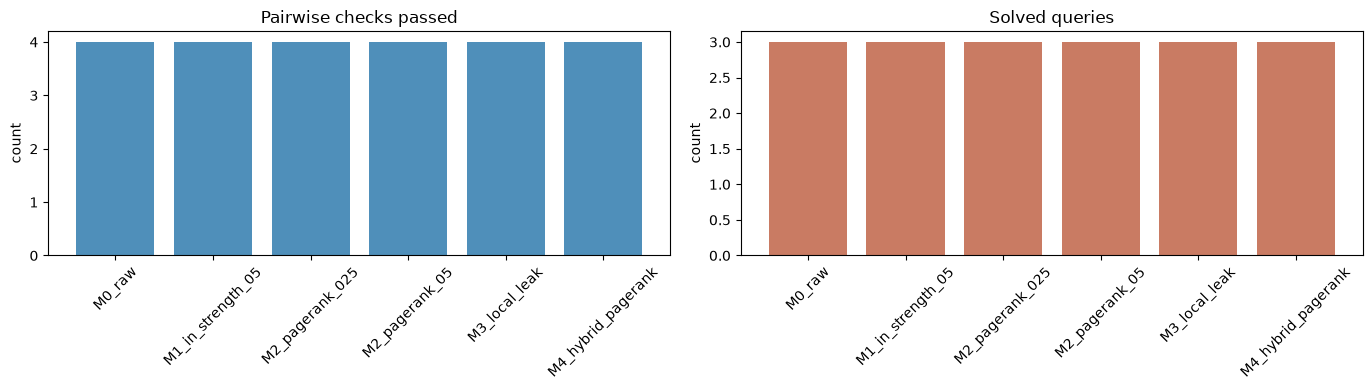

In [11]:
if plt is not None:
    method_names = list(run3["methods"].keys())
    pairwise_passed = [run3["methods"][name]["summary"]["pairwise_passed"] for name in method_names]
    solved_queries = [run3["methods"][name]["summary"]["solved_queries"] for name in method_names]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].bar(method_names, pairwise_passed, color="#4f8fba")
    axes[0].set_title("Pairwise checks passed")
    axes[0].set_ylabel("count")
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].bar(method_names, solved_queries, color="#c97b63")
    axes[1].set_title("Solved queries")
    axes[1].set_ylabel("count")
    axes[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
else:
    print("matplotlib is not available in this environment; skipping plot.")

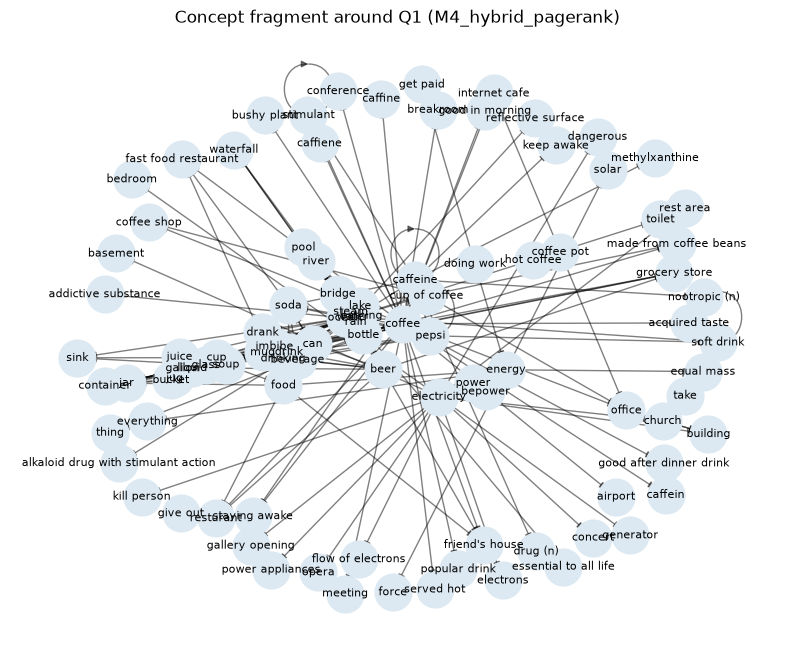

In [12]:
if nx is not None and plt is not None:
    sample_method = "M4_hybrid_pagerank"
    sample_query = next(row for row in run3["methods"][sample_method]["queries"] if row["id"] == VISUALIZE_SAMPLE_QUERY)
    # Readable fragment: anchors + top scored concept nodes from the chosen query.
    fragment = set(sample_query["anchor_ids"])
    resolved_ids = [item["node_id"] for item in sample_query["resolved_correct"] + sample_query["resolved_distractors"]]
    fragment.update(resolved_ids)
    for node_id in list(fragment):
        for edge in run3["graph"].out_edges(node_id):
            if run3["graph"].nodes[edge.dst].node_kind == "concept":
                fragment.add(edge.dst)

    H = nx.DiGraph()
    for node_id in fragment:
        H.add_node(node_id, label=run3["graph"].nodes[node_id].content)
    for node_id in fragment:
        for edge in run3["graph"].out_edges(node_id):
            if edge.dst in fragment:
                H.add_edge(node_id, edge.dst, weight=edge.weight)

    pos = nx.spring_layout(H, seed=7)
    plt.figure(figsize=(10, 8))
    nx.draw_networkx_nodes(H, pos, node_size=700, node_color="#dce9f2")
    nx.draw_networkx_edges(H, pos, arrows=True, alpha=0.5)
    nx.draw_networkx_labels(H, pos, labels=nx.get_node_attributes(H, "label"), font_size=8)
    plt.title(f"Concept fragment around {VISUALIZE_SAMPLE_QUERY} ({sample_method})")
    plt.axis("off")
    plt.show()
else:
    print("networkx and/or matplotlib unavailable; skipping fragment visualization.")

In [13]:
if RUN_RADIUS_4:
    run4 = run_suite(ALT_RADIUS)
    print(f"Built radius={run4['radius']} seeded subgraph.")

    comparison_rows = []
    for method_name in run3["methods"]:
        left = run3["methods"][method_name]["summary"]
        right = run4["methods"][method_name]["summary"]
        comparison_rows.append(
            {
                "method": method_name,
                "pairwise_r3": f"{left['pairwise_passed']}/{left['pairwise_total']}",
                "pairwise_r4": f"{right['pairwise_passed']}/{right['pairwise_total']}",
                "solved_r3": f"{left['solved_queries']}/{left['queries_with_decision']}",
                "solved_r4": f"{right['solved_queries']}/{right['queries_with_decision']}",
            }
        )
    print_table(comparison_rows, ["method", "pairwise_r3", "pairwise_r4", "solved_r3", "solved_r4"])
else:
    print("Set RUN_RADIUS_4 = True in the config cell to run the radius-4 stability check.")

Set RUN_RADIUS_4 = True in the config cell to run the radius-4 stability check.


In [14]:
def qualitative_winner(bundle: dict) -> str:
    best = None
    best_key = None
    for method_name, payload in bundle["methods"].items():
        summary = payload["summary"]
        key = (
            summary["pairwise_passed"],
            summary["solved_queries"],
            summary["total_margin"],
        )
        if best is None or key > best_key:
            best = payload["config"]["label"]
            best_key = key
    return best


winner = qualitative_winner(run3)
print("Radius-3 qualitative winner:", winner)
print(
    "\nInterpretation checklist:"
    "\n- Compare this winner against M0_raw on pairwise checks."
    "\n- Inspect whether top-k looks semantically sharper, not only numerically better."
    "\n- If M4 wins, the 6d hybrid picture survived at least one real subgraph transfer check."
    "\n- If M1 or M2 wins instead, local leak may be weaker without manual capacity than it looked on 6c."
    "\n- If broad-topic queries collapse into narrow items, the correction is over-aggressive."
)

Radius-3 qualitative winner: M2 raw + PageRank^0.5

Interpretation checklist:
- Compare this winner against M0_raw on pairwise checks.
- Inspect whether top-k looks semantically sharper, not only numerically better.
- If M4 wins, the 6d hybrid picture survived at least one real subgraph transfer check.
- If M1 or M2 wins instead, local leak may be weaker without manual capacity than it looked on 6c.
- If broad-topic queries collapse into narrow items, the correction is over-aggressive.
